In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
stroke_data = pd.read_csv("stroke-prediction.csv")
X = stroke_data.drop(columns = ["stroke", "id"])
y = stroke_data["stroke"]
names = stroke_data.columns
print(names)

In [ ]:
features = ["age", "avg_glucose_level"]

X2 = StandardScaler().fit_transform(X[features])
Sigma = np.cov(X2, rowvar = False)

print("Covariance matrix:\n ", Sigma.round(2))

fig, ax = plt.subplots(figsize = (4, 3.6))
ax.scatter(X2[:, 0], X2[:, 1], s = 6, alpha = 0.5)
ax.set_xlabel("age (standardised)")
ax.set_ylabel("average glucose level (standardised)")
_ = ax.set_aspect("equal")

In [ ]:
thetas = np.linspace(0, np.pi, 180)
var_z = [np.var(X2 @ np.array([np.cos(t), np.sin(t)]), ddof = 1) for t in thetas]
best = thetas[np.argmax(var_z)]
worst = thetas[np.argmin(var_z)]

print(f"Principle axes 1: {best:.2f}")
print(f"Principal axes 2: {worst:.2f}")
print(f"Therefore, total variance is: {best + worst:.2f}")

fig, axs = plt.subplots(1, 2, figsize = (6, 2.6))
axs[0].plot(np.degrees(thetas), var_z)
axs[0].axvline(np.degrees(best), color = "k", linestyle = ":")
axs[0].axvline(np.degrees(worst), color = "k", linestyle = ":")
axs[0].set_xlabel(r"angle $\theta$ (degrees)")
axs[0].set_ylabel("variance of projection")
axs[1].scatter(X2[:, 0], X2[:, 1], s = 3, alpha = 0.4)
for t, c in [(best, "C1"), (best + np.pi / 2, "C2")]:
    axs[1].plot([-3 * np.cos(t), 3 * np.cos(t)], [-3 * np.sin(t), 3 * np.sin(t)], c)
axs[1].set_aspect("equal")
plt.tight_layout()

In [ ]:
evals, evecs = np.linalg.eigh(Sigma)
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]
print("eigenvalues", evals.round(2), " sum:", evals.sum().round(2))
print("eigenvectors (columns):\n", evecs.round(3))
Z2 = X2 @ evecs
print("covariance of the scores:\n", np.cov(Z2, rowvar = False).round(2))

In [ ]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

In [ ]:
# Convert categorical columns to numeric dummy variables
Xw = pd.get_dummies(X, drop_first=False, dtype=float)

# Convert any missing values, such as N/A in bmi, to the column median
Xw = Xw.apply(pd.to_numeric, errors="coerce")
Xw = Xw.fillna(Xw.median())

feature_names = Xw.columns.to_numpy()

raw = PCA().fit(Xw)
std = make_pipeline(StandardScaler(), PCA()).fit(Xw)

print("explained variance ratio, raw:",
      raw.explained_variance_ratio_[:4].round(3))
print("explained variance ratio, scaled:",
      std[-1].explained_variance_ratio_[:4].round(3))

j = np.argmax(np.abs(raw.components_[0]))

print(f"raw PC1 is dominated by '{feature_names[j]}'"
      f"(variance {Xw.iloc[:, j].var():.0f}; "
      f"next largest {np.sort(Xw.var(axis=0))[-2]:.0f})")

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(5, shuffle=True, random_state = 0)

Zw = std.transform(Xw)

views = [("average glucose level vs age", Xw.iloc[:, :2].to_numpy()), 
        ("PCA, not scaled", raw.transform(Xw)[:, :2]), 
        ("PCA, standardized", Zw[:, :2])]

fig, axs = plt.subplots(1, 3, figsize = (18, 6))
for ax, (title, P2) in zip(axs, views):
    acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), P2, y, cv = cv).mean()
    for c in range(3):
        ax.scatter(P2[y == c, 0], P2[y == c, 1], s = 6, label = f"class {c}")
    ax.set_title(f"{title}\nCV accuracy {acc:.2f}", fontsize = 9)
    ax.set_xticks([]); ax.set_yticks([])
_ = axs[0].legend(fontsize = 7)

## IGNORE EVERYTHING ABOVE THIS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm

MY_FILE = "stroke-prediction.csv"
raw = pd.read_csv(MY_FILE)

TARGET = "stroke"
DROP = ["id"]

df = raw.drop(columns=DROP)
y = df[TARGET]
X = df.drop(columns=[TARGET])

numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])

C = 1.0  # SVM regularization parameter
models = {
    "SVC linear": svm.SVC(kernel="linear", C=C, class_weight = 'balanced'),
    "LinearSVC": svm.LinearSVC(C=C, max_iter=10000, class_weight = 'balanced'),
    "SVC rbf": svm.SVC(kernel="rbf", gamma=0.7, C=C, class_weight = 'balanced'),
    "SVC poly": svm.SVC(kernel="poly", degree=3, gamma="auto", C=C, class_weight = 'balanced'),
}

Xm_train, X_test, ym_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

def compare(models, X, y, cv, scoring=("roc_auc", "recall")):
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("prep", preprocess), ("model", model)])
        s = cross_validate(pipe, X, y, cv=cv, scoring=list(scoring), return_train_score=True)
        row = {"model": name}
        for m in scoring:
            row[m] = s["test_" + m].mean()
            row[m + " spread"] = s["test_" + m].std()
        row["training " + scoring[0]] = s["train_" + scoring[0]].mean()
        row["fit ms"] = 1000 * s["fit_time"].mean()
        row["score ms per 1000 rows"] = 1000 * s["score_time"].mean() / (len(X) / cv.get_n_splits()) * 1000
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").round(3)

results = compare(models, Xm_train, ym_train, cv)
results

,roc_auc,roc_auc spread,recall,recall spread,training roc_auc,fit ms,score ms per 1000 rows
model,,,,,,,
SVC linear,0.843,0.032,0.804,0.094,0.854,235.929,72.774
LinearSVC,0.845,0.029,0.824,0.103,0.856,23.134,22.671
SVC rbf,0.704,0.036,0.176,0.064,0.990,190.776,216.294
SVC poly,0.808,0.029,0.643,0.081,0.891,185.442,87.028


#### Searching for dial, starting with C

In [4]:
from sklearn.model_selection import GridSearchCV

METRIC = "roc_auc"
TUNE = "LinearSVC"
GRID = {"model__C": np.logspace(-4, 3, 8)}

pipe = Pipeline([("prep", preprocess), ("model", models[TUNE])])

search = GridSearchCV(pipe, GRID, cv=cv, scoring=METRIC, return_train_score=True)
search.fit(Xm_train, ym_train)

grid_table = pd.DataFrame(search.cv_results_)[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
print("best:", search.best_params_, " cross-validated {}: {:.4f}".format(METRIC, search.best_score_))

models[TUNE + ", tuned"] = search.best_estimator_.named_steps["model"]   # model only; compare() adds prep
grid_table.round(4)

best: {'model__C': np.float64(0.001)}  cross-validated roc_auc: 0.8460


,params,mean_train_score,mean_test_score,std_test_score
0,{'model__C': 0.0001},0.8429,0.8376,0.0259
1,{'model__C': 0.001},0.8549,0.8460,0.0280
2,{'model__C': 0.01},0.8558,0.8459,0.0296
3,{'model__C': 0.1},0.8560,0.8447,0.0291
4,{'model__C': 1.0},0.8560,0.8446,0.0290
5,{'model__C': 10.0},0.8560,0.8446,0.0290
6,{'model__C': 100.0},0.8560,0.8446,0.0290
7,{'model__C': 1000.0},0.8560,0.8446,0.0290


only a 0.001 improvement on roc_auc, so lets change gamma

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.metrics import make_scorer, fbeta_score

SCORING = {
    "f2": make_scorer(fbeta_score, beta=2),
    "recall": "recall",
    "precision": "precision",
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
}
METRIC = "f2"

def tune(name, grid):
    """Grid-search one model from `models` inside the full pipeline, using CV on the training split."""
    pipe = Pipeline([("prep", preprocess), ("model", models[name])])
    search = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit=METRIC,
                          return_train_score=True, n_jobs=-1)
    search.fit(Xm_train, ym_train)

    cols = ["params", f"mean_train_{METRIC}"] + [f"mean_test_{m}" for m in SCORING] + [f"std_test_{METRIC}"]
    table = pd.DataFrame(search.cv_results_)[cols].sort_values(f"mean_test_{METRIC}", ascending=False)

    print(f"{name} best: {search.best_params_}")
    print(f"  cross-validated {METRIC}: {search.best_score_:.4f}")

    models[name + ", tuned"] = search.best_estimator_.named_steps["model"]
    return search, table.round(4)

In [12]:
Cs = np.logspace(-4, 3, 8)
weights = [None, "balanced"]
scalers = [StandardScaler(), RobustScaler(), MinMaxScaler()]

grid_linear = [
    # l2 + hinge only works with dual=True
    {"model__penalty": ["l2"], "model__loss": ["hinge"], "model__dual": [True],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
    # l2 + squared_hinge
    {"model__penalty": ["l2"], "model__loss": ["squared_hinge"], "model__dual": [False],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
    # l1 only works with squared_hinge and dual=False
    {"model__penalty": ["l1"], "model__loss": ["squared_hinge"], "model__dual": [False],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
]

search_lin, table_lin = tune("LinearSVC", grid_linear)
table_lin.head(10)

LinearSVC best: {'model__C': np.float64(0.1), 'model__class_weight': 'balanced', 'model__dual': False, 'model__loss': 'squared_hinge', 'model__penalty': 'l2', 'prep__num__scale': StandardScaler()}
  cross-validated f2: 0.4089


,params,mean_train_f2,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_f2
69,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4157,0.4089,0.8244,0.1357,0.8447,0.1917,0.0430
77,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4161,0.4084,0.8244,0.1354,0.8447,0.1918,0.0427
131,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4163,0.4084,0.8244,0.1354,0.8446,0.1917,0.0427
83,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4163,0.4084,0.8244,0.1354,0.8446,0.1917,0.0427
76,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4162,0.4084,0.8244,0.1354,0.8447,0.1918,0.0427
75,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4163,0.4084,0.8244,0.1354,0.8446,0.1917,0.0427
123,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4161,0.4084,0.8244,0.1354,0.8447,0.1918,0.0427
70,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4156,0.4083,0.8244,0.1353,0.8448,0.1914,0.0432
95,"{'model__C': 1000.0, 'model__class_weight': 'b...",0.4163,0.4083,0.8244,0.1353,0.8446,0.1917,0.0431
129,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4162,0.4083,0.8244,0.1353,0.8446,0.1917,0.0431


In [7]:
grid_rbf = {
    "model__C": np.logspace(-3, 3, 7),
    "model__gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "model__class_weight": [None, "balanced"],
}

search_rbf, table_rbf = tune("SVC rbf", grid_rbf)
table_rbf.head(10)

SVC rbf best: {'model__C': np.float64(10.0), 'model__class_weight': 'balanced', 'model__gamma': 0.01}
  cross-validated f2: 0.4025


,params,mean_train_f2,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_f2
47,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4357,0.4025,0.7894,0.1362,0.8319,0.1993,0.0393
46,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4135,0.4017,0.8244,0.1318,0.8453,0.1891,0.0399
56,"{'model__C': 100.0, 'model__class_weight': 'ba...",0.4184,0.4000,0.8044,0.1331,0.8425,0.1972,0.0406
37,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4116,0.3991,0.8294,0.1299,0.8439,0.2030,0.0356
25,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4083,0.3965,0.8395,0.1276,0.8338,0.1892,0.0199
28,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4070,0.3964,0.8395,0.1275,0.8350,0.1897,0.0258
27,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.3941,0.3963,0.8745,0.1244,0.8459,0.1912,0.0220
36,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.3956,0.3948,0.8695,0.1241,0.8471,0.1900,0.0240
66,"{'model__C': 1000.0, 'model__class_weight': 'b...",0.4336,0.3934,0.7740,0.1328,0.8315,0.1972,0.0463
26,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.3975,0.3880,0.7344,0.1345,0.8307,0.1798,0.0384


In [15]:
grid_poly = {
    "model__degree": [2, 3, 4],
    "model__coef0": [0, 1],
    "model__C": [0.0001, 0.001, 1, 10],          # large C with poly can take a very long time
    "model__gamma": ["scale", 0.01, 0.1],
    "model__class_weight": ["balanced"],
}

search_poly, table_poly = tune("SVC poly", grid_poly)
table_poly.head(10)

SVC poly best: {'model__C': 0.001, 'model__class_weight': 'balanced', 'model__coef0': 1, 'model__degree': 4, 'model__gamma': 0.1}
  cross-validated f2: 0.4158


,params,mean_train_f2,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_f2
35,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4279,0.4158,0.7794,0.1453,0.8387,0.2125,0.0238
33,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4283,0.4123,0.7944,0.1412,0.8399,0.2155,0.0256
55,"{'model__C': 10, 'model__class_weight': 'balan...",0.4312,0.4079,0.7944,0.1387,0.8376,0.2066,0.0414
64,"{'model__C': 10, 'model__class_weight': 'balan...",0.4261,0.4020,0.7944,0.1354,0.8370,0.2035,0.0429
46,"{'model__C': 1, 'model__class_weight': 'balanc...",0.4136,0.4010,0.8195,0.1319,0.8453,0.1968,0.0399
32,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4148,0.4010,0.7192,0.1449,0.8353,0.1978,0.0387
30,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4213,0.4004,0.7342,0.1422,0.8370,0.2069,0.0357
49,"{'model__C': 1, 'model__class_weight': 'balanc...",0.4167,0.3996,0.8094,0.1323,0.8429,0.2072,0.0429
52,"{'model__C': 1, 'model__class_weight': 'balanc...",0.4239,0.3984,0.7944,0.1332,0.8401,0.2040,0.0389
37,"{'model__C': 1, 'model__class_weight': 'balanc...",0.4110,0.3934,0.6791,0.1468,0.8350,0.2078,0.0405


In [16]:
for name, s in [("LinearSVC", search_lin), ("SVC rbf", search_rbf), ("SVC poly", search_poly)]:
    best_C = s.best_params_["model__C"]
    grid_Cs = sorted({p["model__C"] for p in s.cv_results_["params"]})
    if best_C in (grid_Cs[0], grid_Cs[-1]):
        print(f"{name}: best C={best_C} is at the edge of the grid; widen the range")

In [17]:
results = compare(models, Xm_train, ym_train, cv)
results

,roc_auc,roc_auc spread,recall,recall spread,training roc_auc,fit ms,score ms per 1000 rows
model,,,,,,,
SVC linear,0.843,0.032,0.804,0.094,0.854,236.147,91.780
LinearSVC,0.845,0.029,0.824,0.103,0.856,21.656,22.018
SVC rbf,0.704,0.036,0.176,0.064,0.990,187.667,233.275
SVC poly,0.808,0.029,0.643,0.081,0.891,173.777,84.371
"LinearSVC, tuned",0.845,0.029,0.824,0.103,0.856,21.203,20.838
"SVC rbf, tuned",0.832,0.029,0.789,0.098,0.873,208.594,234.109
"SVC poly, tuned",0.839,0.027,0.779,0.061,0.856,214.003,102.579


### Proceeding with LinearSVC, tuned. Let's try adjusting the threshold to see if we can get better recall

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

best = search_lin.best_estimator_
final = Pipeline([
    ("prep", best.named_steps["prep"]),
    ("model", CalibratedClassifierCV(best.named_steps["model"], method="sigmoid", cv=5)),
])

proba = cross_val_predict(final, Xm_train, ym_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0, 0.1, 0.01):
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(ym_train, p, zero_division=0),
                 "recall": recall_score(ym_train, p),
                 "share flagged": p.mean()})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,share flagged
0,0.00,0.049,1.000,1.000
1,0.01,0.075,0.990,0.645
2,0.02,0.093,0.950,0.500
3,0.03,0.109,0.915,0.410
4,0.04,0.123,0.874,0.347
5,0.05,0.134,0.824,0.299
6,0.06,0.146,0.779,0.260
7,0.07,0.157,0.729,0.226
8,0.08,0.165,0.698,0.205
9,0.09,0.171,0.658,0.188


              precision    recall  f1-score   support

           0       0.99      0.69      0.81       972
           1       0.12      0.80      0.20        50

    accuracy                           0.69      1022
   macro avg       0.55      0.74      0.51      1022
weighted avg       0.94      0.69      0.78      1022

test set at threshold 0.04: precision 0.117, recall 0.800


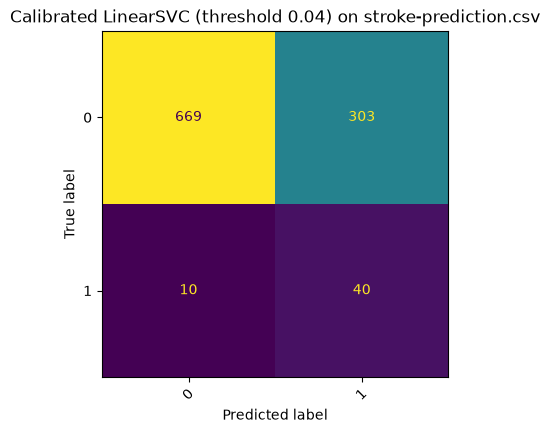

In [26]:
THRESHOLD = 0.04

final.fit(Xm_train, ym_train)

p_test = (final.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(y_test, p_test, zero_division=0))
print("test set at threshold {}: precision {:.3f}, recall {:.3f}".format(
    THRESHOLD, precision_score(y_test, p_test, zero_division=0), recall_score(y_test, p_test)))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, p_test, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"Calibrated LinearSVC (threshold {THRESHOLD}) on " + MY_FILE)
plt.show()